# 44. Random Matrices and the Spectra of Learning
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

In [2]:
from math import comb
rng = np.random.default_rng(0); n = 1000; G = rng.normal(size=(n, n)); Wg = (G + G.T) / np.sqrt(2 * n); ev = np.linalg.eigvalsh(Wg)
print("k   (1/n) tr W^(2k)   Catalan C_k")
for k in range(1, 7): print(f"{k}   {np.mean(ev ** (2 * k)):12.4f}   {comb(2 * k, k) // (k + 1):8d}")

k   (1/n) tr W^(2k)   Catalan C_k
1         1.0004          1
2         2.0022          2
3         5.0128          5
4        14.0636         14
5        42.2885         42
6       133.2403        132


The semicircle law and its universality. Left: eigenvalues of a $2000\times2000$ GOE matrix (histogram) and the semicircle density $\frac1{2\pi}\sqrt{4-x^2}$. Right: the same for a symmetric matrix with independent entries $\pm1/\sqrt n$ (random signs); only the variance of the entries matters in the limit.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


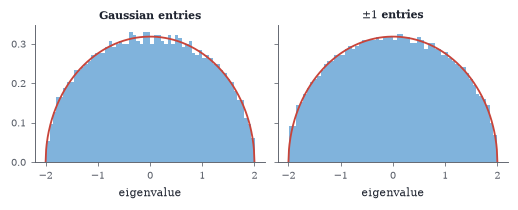

In [3]:
rng = np.random.default_rng(1); n = 2000; xs = np.linspace(-2, 2, 400); sc = np.sqrt(4 - xs**2) / (2 * np.pi)
G = rng.normal(size=(n, n)); E1 = np.linalg.eigvalsh((G + G.T) / np.sqrt(2 * n))
S = np.triu(rng.choice([-1.0, 1.0], size=(n, n))); S = S + np.triu(S, 1).T; E2 = np.linalg.eigvalsh(S / np.sqrt(n))
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8), sharey=True)
for ax, E, t in [(axs[0], E1, "Gaussian entries"), (axs[1], E2, r"$\pm1$ entries")]:
    ax.hist(E, bins=60, density=True, color=SKY, alpha=0.85); ax.plot(xs, sc, color=RED); ax.set_title(t, fontsize=7); ax.set_xlabel("eigenvalue")

Level repulsion. Spacings between consecutive eigenvalues in the middle of the spectrum of $200$ GOE matrices of size $400$, rescaled to mean $1$ using the semicircle density (blue histogram), against the spacings of independent uniform points (grey histogram). The curves are the Wigner surmise $\frac{\pi s}2e^{-\pi s^2/4}$ (red) and the exponential density $e^{-s}$ (black). Eigenvalues avoid each other; independent points do not.

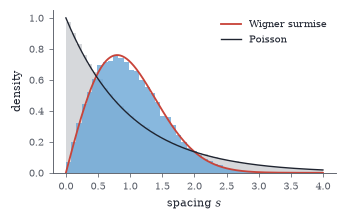

In [4]:
rng = np.random.default_rng(2); n = 400; sp = []
for _ in range(200):
    G = rng.normal(size=(n, n)); ev = np.linalg.eigvalsh((G + G.T) / np.sqrt(2 * n)); mid = ev[n // 4: 3 * n // 4]
    sp.append(np.diff(mid) * n * np.sqrt(4 - ((mid[1:] + mid[:-1]) / 2) ** 2) / (2 * np.pi))
sp = np.concatenate(sp); sp /= sp.mean(); u = np.sort(rng.uniform(size=200000)); ps = np.diff(u) * len(u)
s = np.linspace(0, 4, 300); fig, ax = plt.subplots(figsize=(W * 0.66, 1.9))
ax.hist(ps, bins=np.linspace(0, 4, 50), density=True, color=GRAY, alpha=0.35); ax.hist(sp, bins=np.linspace(0, 4, 50), density=True, color=SKY, alpha=0.8)
ax.plot(s, np.pi * s / 2 * np.exp(-np.pi * s**2 / 4), color=RED, label="Wigner surmise"); ax.plot(s, np.exp(-s), color=INK, lw=0.9, label="Poisson")
ax.set_xlabel("spacing $s$"); ax.set_ylabel("density"); ax.legend(fontsize=6.5, frameon=False)

Edge fluctuations. Histograms of $n^{2/3}(\lambda_{\max}-2)$ for GOE matrices of size $n=50$, $500$ and $5000$ ($2000$ samples each, using the tridiagonal model); the three histograms nearly coincide, confirming the $n^{-2/3}$ scale, and their common mean and spread match the Tracy–Widom values $-1.21$ and $1.27$ (dashed line: the mean).

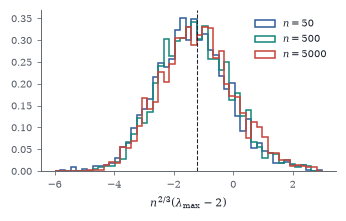

In [5]:
from scipy.linalg import eigvalsh_tridiagonal
rng = np.random.default_rng(3); fig, ax = plt.subplots(figsize=(W * 0.66, 1.9)); stats = []
for n, c in [(50, BLUE), (500, TEAL), (5000, RED)]:
    xi = []
    for _ in range(2000):
        d = rng.normal(size=n) * np.sqrt(2 / n); e = np.sqrt(rng.chisquare(np.arange(n - 1, 0, -1))) / np.sqrt(n)
        xi.append((eigvalsh_tridiagonal(d, e, select="i", select_range=(n - 1, n - 1))[0] - 2) * n ** (2 / 3))
    xi = np.array(xi); stats.append((n, xi.mean(), xi.std())); ax.hist(xi, bins=np.linspace(-6, 3, 50), density=True, histtype="step", color=c, lw=1.0, label=f"$n={n}$")
ax.axvline(-1.2065, color=INK, ls="--", lw=0.7); ax.set_xlabel(r"$n^{2/3}(\lambda_{\max}-2)$"); ax.legend(fontsize=6.5, frameon=False)

In [6]:
for n, mu_, sd_ in stats: print(f"n={n:5d}:  mean {mu_:+.3f}   std {sd_:.3f}")

n=   50:  mean -1.366   std 1.238
n=  500:  mean -1.254   std 1.217
n= 5000:  mean -1.186   std 1.268


The Marchenko–Pastur law for $\gamma=p/N=0.1$, $0.5$ and $1$ ($p=500$). Histograms of the eigenvalues of $\frac1NXX^{T}$ for Gaussian $X$, with the densities $\rho_\gamma$. As $\gamma$ grows the spectrum spreads and, at $\gamma=1$, reaches down to $0$ with an inverse-square-root singularity; every true eigenvalue is $1$.

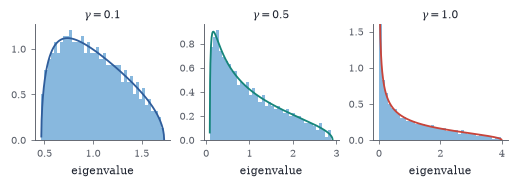

In [7]:
rng = np.random.default_rng(4); p = 500; fig, axs = plt.subplots(1, 3, figsize=(W, 1.6), sharey=False)
for ax, gam, c in zip(axs, [0.1, 0.5, 1.0], [BLUE, TEAL, RED]):
    Nn = int(p / gam); Xm = rng.normal(size=(p, Nn)); ev = np.linalg.eigvalsh(Xm @ Xm.T / Nn); a, b = (1 - np.sqrt(gam)) ** 2, (1 + np.sqrt(gam)) ** 2
    xx = np.linspace(a + 1e-4, b, 400); ax.hist(ev, bins=40, density=True, color=SKY, alpha=0.8); ax.plot(xx, np.sqrt((b - xx) * (xx - a)) / (2 * np.pi * gam * xx), color=c)
    ax.set_title(rf"$\gamma={gam}$", fontsize=7); ax.set_xlabel("eigenvalue")
    if gam == 1.0: ax.set_ylim(0, 1.6)

The BBP transition for sample covariance, $p=400$, $N=800$ ($\gamma=0.5$, threshold $\theta=\sqrt\gamma\approx0.71$, dotted). Left: the top eigenvalue of the sample covariance (dots, average of $10$ samples) against the spike strength $\theta$, with the prediction $(1+\theta)(1+\gamma/\theta)$ above the threshold and the bulk edge $(1+\sqrt\gamma)^2$ below. Right: the squared overlap of the top sample eigenvector with the true direction, with the prediction $\frac{1-\gamma/\theta^2}{1+\gamma/\theta}$.

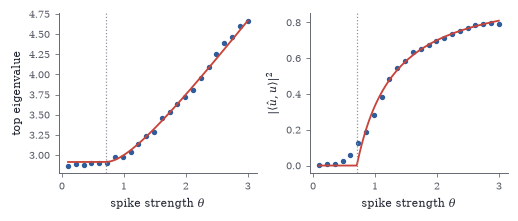

In [8]:
rng = np.random.default_rng(5); p, Nn = 400, 800; gam = p / Nn; ths = np.linspace(0.1, 3, 24); top, ov = [], []
u = np.zeros(p); u[0] = 1
for th in ths:
    tl, ol = [], []
    for _ in range(10):
        Z = rng.normal(size=(p, Nn)); Z[0] *= np.sqrt(1 + th); Sm = Z @ Z.T / Nn; w, V = np.linalg.eigh(Sm); tl.append(w[-1]); ol.append(V[0, -1] ** 2)
    top.append(np.mean(tl)); ov.append(np.mean(ol))
tt = np.linspace(0.1, 3, 300); crit = np.sqrt(gam); fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
axs[0].plot(ths, top, "o", color=BLUE, ms=2.5); axs[0].plot(tt, np.where(tt > crit, (1 + tt) * (1 + gam / tt), (1 + crit) ** 2), color=RED)
axs[1].plot(ths, ov, "o", color=BLUE, ms=2.5); axs[1].plot(tt, np.where(tt > crit, (1 - gam / tt**2) / (1 + gam / tt), 0), color=RED)
for ax, yl in zip(axs, ["top eigenvalue", r"$|\langle\hat u,u\rangle|^2$"]): ax.axvline(crit, color=GRAY, ls=":", lw=0.8); ax.set_xlabel(r"spike strength $\theta$"); ax.set_ylabel(yl)

Adding two reflections. Left: if $A$ and $B$ both have eigenvalues $\pm1$ (half each) and commute, $A+B$ has the three eigenvalues $-2,0,2$ with weights $\frac14,\frac12,\frac14$. Right: with $B$ replaced by $QBQ^{T}$ for a random orthogonal $Q$ ($n=2000$), the eigenvalues of the sum fill $[-2,2]$ with the arcsine density $\frac1{\pi\sqrt{4-x^2}}$ (red), the free convolution of the two spectra.

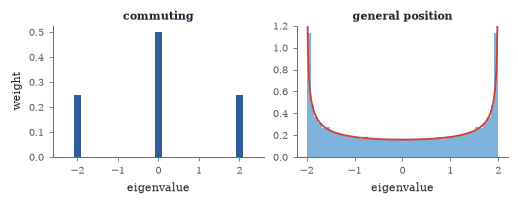

In [9]:
rng = np.random.default_rng(6); n = 2000; D = np.diag(np.r_[np.ones(n // 2), -np.ones(n // 2)]); Qh, Rh = np.linalg.qr(rng.normal(size=(n, n))); Qh = Qh * np.sign(np.diag(Rh))
ev = np.linalg.eigvalsh(D + Qh @ D @ Qh.T); fig, axs = plt.subplots(1, 2, figsize=(W, 1.75))
axs[0].bar([-2, 0, 2], [0.25, 0.5, 0.25], width=0.18, color=BLUE); axs[0].set_xlim(-2.6, 2.6); axs[0].set_title("commuting", fontsize=7); axs[0].set_ylabel("weight")
xs = np.linspace(-1.995, 1.995, 400); axs[1].hist(ev, bins=50, density=True, color=SKY, alpha=0.85); axs[1].plot(xs, 1 / (np.pi * np.sqrt(4 - xs**2)), color=RED); axs[1].set_ylim(0, 1.2); axs[1].set_title("general position", fontsize=7)
for ax in axs: ax.set_xlabel("eigenvalue")

Eigenvalues of non-symmetric random matrices ($n=1000$, entries of variance $\frac1n$). Left: independent Gaussian entries (the real Ginibre ensemble): the eigenvalues fill the unit disc uniformly, with an excess of exactly real eigenvalues (red) along the axis. Right: entries with correlation $\tau=0.5$ between $g_{ij}$ and $g_{ji}$: the eigenvalues fill the ellipse with semi-axes $1.5$ and $0.5$ (dashed).

Text(0.5, 1.0, 'elliptic law, $\\tau=0.5$')

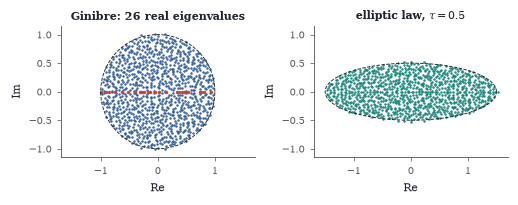

In [10]:
rng = np.random.default_rng(7); n = 1000; G = rng.normal(size=(n, n)) / np.sqrt(n); ev = np.linalg.eigvals(G)
tau = 0.5; Hs = rng.normal(size=(n, n)); Sy = (Hs + Hs.T) / np.sqrt(2); Hk = rng.normal(size=(n, n)); Sk = (Hk - Hk.T) / np.sqrt(2); E = (np.sqrt((1 + tau) / 2) * Sy + np.sqrt((1 - tau) / 2) * Sk) / np.sqrt(n); ev2 = np.linalg.eigvals(E)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0)); t = np.linspace(0, 2 * np.pi, 300)
re = np.abs(ev.imag) < 1e-9; axs[0].plot(ev.real[~re], ev.imag[~re], ".", color=BLUE, ms=1.2); axs[0].plot(ev.real[re], ev.imag[re], ".", color=RED, ms=2.5); axs[0].plot(np.cos(t), np.sin(t), "--", color=INK, lw=0.6)
axs[1].plot(ev2.real, ev2.imag, ".", color=TEAL, ms=1.2); axs[1].plot((1 + tau) * np.cos(t), (1 - tau) * np.sin(t), "--", color=INK, lw=0.6)
for ax in axs: ax.set_aspect("equal"); ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.15, 1.15); ax.set_xlabel("Re"); ax.set_ylabel("Im")
axs[0].set_title(f"Ginibre: {re.sum()} real eigenvalues", fontsize=7); axs[1].set_title(r"elliptic law, $\tau=0.5$", fontsize=7)

Edges and tails. Complementary distribution function (fraction of eigenvalues larger than $\lambda$, log–log scale) of $\frac1NW^{T}W$ for $W\in\R^{2000\times1000}$ with independent entries: Gaussian (blue), whose spectrum ends sharply at the Marchenko–Pastur edge $(1+\sqrt{1/2})^2\approx2.9$ (dotted); Student-$t$ entries with $2.2$ degrees of freedom (red), normalized to unit variance (finite variance, infinite fourth moment), whose largest eigenvalues extend far beyond the edge in a power-law tail; and Gaussian entries plus a rank-$5$ learned signal (teal), which adds five outliers to an otherwise unchanged bulk.

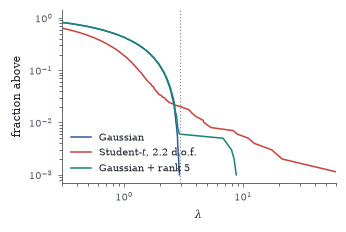

In [11]:
rng = np.random.default_rng(8); Nr, pc = 2000, 1000
def ccdf(Wm): ev = np.sort(np.linalg.eigvalsh(Wm.T @ Wm / Nr))[::-1]; return ev, np.arange(1, len(ev) + 1) / len(ev)
Wg = rng.normal(size=(Nr, pc)); Wt = rng.standard_t(2.2, size=(Nr, pc)) / np.sqrt(2.2 / 0.2); Uo = rng.normal(size=(Nr, 5)); Vo = rng.normal(size=(pc, 5)); Ws = Wg + 2.5 * Uo @ Vo.T / np.sqrt(pc)
fig, ax = plt.subplots(figsize=(W * 0.66, 2.0))
for Wm, c, lab in [(Wg, BLUE, "Gaussian"), (Wt, RED, "Student-$t$, 2.2 d.o.f."), (Ws, TEAL, "Gaussian + rank 5")]: ev, cc = ccdf(Wm); ax.loglog(ev, cc, color=c, lw=1.0, label=lab)
ax.axvline((1 + np.sqrt(0.5)) ** 2, color=GRAY, ls=":", lw=0.8); ax.set_xlim(0.3, 60); ax.set_xlabel(r"$\lambda$"); ax.set_ylabel("fraction above"); ax.legend(fontsize=6.5, frameon=False, loc="lower left")

In [12]:
rng = np.random.default_rng(9); n = 2000; G = rng.normal(size=(n, n)); ev = np.linalg.eigvalsh((G + G.T) / np.sqrt(2 * n))
for z in (0.5 + 0.1j, 0.5 + 0.01j):
    m_emp = np.mean(1 / (ev - z)); r = np.sqrt(z * z - 4 + 0j); m1, m2 = (-z + r) / 2, (-z - r) / 2; m_th = m1 if m1.imag > 0 else m2
    print(f"z={z}:  empirical {m_emp:.4f}   formula {m_th:.4f}   (1/pi) Im m = {m_th.imag / np.pi:.4f}")
print("semicircle density at 0.5:", round(np.sqrt(4 - 0.25) / (2 * np.pi), 4))

z=(0.5+0.1j):  empirical -0.2397+0.9129j   formula -0.2371+0.9196j   (1/pi) Im m = 0.2927
z=(0.5+0.01j):  empirical -0.2526+0.9565j   formula -0.2487+0.9633j   (1/pi) Im m = 0.3066
semicircle density at 0.5: 0.3082


In [13]:
rng = np.random.default_rng(10); print("4000 x 1000:", round(np.linalg.cond(rng.normal(size=(4000, 1000))), 3))
for n in (50, 200, 800): print(f"{n} x {n}: median of kappa / n over 40 samples = {np.median([np.linalg.cond(rng.normal(size=(n, n))) for _ in range(40)]) / n:.2f}")

4000 x 1000: 2.988
50 x 50: median of kappa / n over 40 samples = 3.14
200 x 200: median of kappa / n over 40 samples = 4.16


800 x 800: median of kappa / n over 40 samples = 3.68


In [14]:
rng = np.random.default_rng(11); n, T = 20, 3000; raw, fixed = [], []
for _ in range(T):
    Qq, Rr = np.linalg.qr(rng.normal(size=(n, n))); raw.append(np.angle(np.linalg.eigvals(Qq))); fixed.append(np.angle(np.linalg.eigvals(Qq * np.sign(np.diag(Rr)))))
for name, a in [("library signs", np.concatenate(raw)), ("corrected", np.concatenate(fixed))]:
    h, _ = np.histogram(np.abs(a), bins=6, range=(0, np.pi)); print(f"{name:14s} eigenangle histogram |theta| in 6 bins:", h)

library signs  eigenangle histogram |theta| in 6 bins: [ 4554 10326 10912 10922 10882 12404]
corrected      eigenangle histogram |theta| in 6 bins: [11008  9436  9664  9352  9544 10996]


In [15]:
rng = np.random.default_rng(12)
for n in (50, 200, 800):
    cnt = np.mean([np.sum(np.abs(np.linalg.eigvals(rng.normal(size=(n, n))).imag) < 1e-9) for _ in range(20)]); print(f"n={n}: average real eigenvalues {cnt:.1f}   sqrt(2n/pi) = {np.sqrt(2 * n / np.pi):.1f}")

n=50: average real eigenvalues 5.6   sqrt(2n/pi) = 5.6


n=200: average real eigenvalues 11.9   sqrt(2n/pi) = 11.3


n=800: average real eigenvalues 23.3   sqrt(2n/pi) = 22.6


In [16]:
rng = np.random.default_rng(13); n = 1500; u = rng.normal(size=n); u /= np.linalg.norm(u)
for th in (0.5, 1.5, 3.0):
    G = rng.normal(size=(n, n)); Y = th * np.outer(u, u) + (G + G.T) / np.sqrt(2 * n); w, V = np.linalg.eigh(Y)
    pred = (th + 1 / th, 1 - 1 / th**2) if th > 1 else (2.0, 0.0)
    print(f"theta={th}: top eigenvalue {w[-1]:.3f} (predicted {pred[0]:.3f}),  overlap {(V[:, -1] @ u) ** 2:.3f} (predicted {pred[1]:.3f})")

theta=0.5: top eigenvalue 1.987 (predicted 2.000),  overlap 0.002 (predicted 0.000)


theta=1.5: top eigenvalue 2.179 (predicted 2.167),  overlap 0.577 (predicted 0.556)


theta=3.0: top eigenvalue 3.302 (predicted 3.333),  overlap 0.890 (predicted 0.889)
